# Learning not to mix tasks: 2-task multi-MNIST

The experiment of `fully_connected.ipynb`, moved from multi-GEOFF to multi-MNIST. In a fully connected network
there are no distractors to remove; the question is whether our method from `distractors.ipynb` learns to keep the
tasks' information apart, and so does as well as with the ideal connectivity, which builds the problem's structure in.

**Problem.** 2-task multi-MNIST, as in the connectivity paper: each sample concatenates 2 independently drawn MNIST
training images, and each task's target is its own image's label. The images are downsampled to 14×14 by averaging
2×2 blocks, which keeps the 16-task runs to minutes. Each pixel is centered on its mean over the training
set, and all pixels are scaled by one standard deviation over every pixel (scaling each pixel by its own would blow
rarely-lit pixels up to values near 250, which would collapse Autostep's step-sizes through its per-row
normalization). It is non-stationary: every 1000 steps, one task (chosen at random) gets a new random mapping from digits to
labels, so each task changes about every 2000 steps. The loss is the sum of each task's softmax cross-entropy.

**Networks.** 392 inputs → 20 LTU hidden units (one per output) → 20 linear outputs (2 groups of 10 logits), each layer with a bias.
- *Fully connected*: every hidden unit reads every input and feeds every output.
- *Ideal connectivity*: 10 hidden units per task, each reading only its own task's image and feeding only its own task's
  logits.

**Learners.** As in `fully_connected.ipynb`, with $\alpha_0 = 10^{-8}$, meta step-size 0.01 and $\tau = 10^4$:
- *ours*: centered hidden units with a matching centered backward pass, and input weights starting at
  $U(-\alpha_0, \alpha_0)$;
- *standard Autostep*: raw hidden units, and input weights starting LeCun uniform.

Each learner trains both networks. 1000k steps and 30 seeds; seed $s$ gives every run the same initial-weight draw, images and
label changes.

**Hypotheses**, on the online accuracy (over every task) averaged over the last 10% of training, pooled over seeds:
- **H1**, ours learns not to mix: fully connected, ours is at most 1 percentage point below ours with ideal
  connectivity.
- **H2**, mixing is a real cost: fully connected, standard Autostep is more than 1 percentage point below standard
  Autostep with ideal connectivity.

Questions 2 and 3, after the results, try fixes for the fully connected network's shortfall.

**Diagnostics**, fixed in advance, for the fully connected runs:
1. *Path purity*: the share of all input → hidden → output path weight (the product of $|w|$ along the path) that
   starts and ends in the same task. 1 means no path crosses tasks; 1/2 that the units mix the tasks evenly. Pooling
   over all paths means a task with almost no paths barely counts.
2. *Allocation*: how evenly the hidden units are split between the tasks, counting each unit for the task whose outputs
   it feeds most. 1 means 10 units each; 0 means all 20 feed one task. An uneven split costs capacity even without
   mixing.

In [1]:
from typing import NamedTuple

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from torchvision import datasets

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

sns.set_theme('notebook', 'white')
%matplotlib inline

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_TASKS = 2
N_PIXELS = 14 * 14                   # MNIST downsampled from 28x28 by averaging 2x2 blocks
N_CLASSES = 10
PERMUTE_PERIOD = 2000 // N_TASKS     # steps between label changes, each of one task chosen at random

# --- Network ---
N_HIDDEN_PER_TASK = N_CLASSES        # one hidden unit per output: 10 per task in the ideal network, 20 in all

# --- Autostep ---
INIT_STEP_SIZE = 1e-8
META_STEP_SIZE = 0.01
TAU = 1e4
EMA_RATE = 1e-3                      # rate of the hidden units' running means (used by ours)

# --- Training ---
NUM_STEPS = 1_000_000
N_SEEDS = 30
N_WINDOWS = 250                      # each window records its mean loss, accuracy and path purity

# --- Generate and test (Question 3) ---
REINIT_PERIOD = 5000                 # steps between resets of the hidden unit with the smallest output weights
REINIT_PERIODS = (1000, 2000, 5000, 10_000, 20_000, 50_000, 100_000)    # the sweep in 3b

# --- Hypotheses ---
FINAL_FRACTION = 0.1                 # accuracy is compared over the last 10% of training ...
ACCURACY_TOLERANCE = 0.01            # ... with this tolerance (1 percentage point)

In [3]:
mnist = datasets.MNIST(root='/tmp/data', train=True, download=True)
images = np.asarray(mnist.data, dtype=np.float32).reshape(-1, 14, 2, 14, 2).mean((2, 4)).reshape(-1, N_PIXELS) / 255.0
IMAGES = jnp.asarray((images - images.mean(0)) / images.std())     # per-pixel centered, one global scale
DIGITS = jnp.asarray(np.asarray(mnist.targets))


class Stream(NamedTuple):
    key: jax.Array
    step: jax.Array
    label_maps: jax.Array     # (task, digit): each task's current label for each digit


def init_stream(key):
    return Stream(key, jnp.array(0), jnp.tile(jnp.arange(N_CLASSES), (N_TASKS, 1)))


def next_sample(stream):
    # One sample: an independent training image per task, concatenated, and each task's label. Every PERMUTE_PERIOD
    # steps, one task chosen at random first gets a new random label mapping.
    key, task_key, map_key, image_key = jax.random.split(stream.key, 4)
    step = stream.step + 1
    changes = (step % PERMUTE_PERIOD == 0) & (jnp.arange(N_TASKS) == jax.random.randint(task_key, (), 0, N_TASKS))
    label_maps = jnp.where(changes[:, None], jax.random.permutation(map_key, N_CLASSES)[None], stream.label_maps)
    index = jax.random.randint(image_key, (N_TASKS,), 0, IMAGES.shape[0])
    labels = label_maps[jnp.arange(N_TASKS), DIGITS[index]]
    return Stream(key, step, label_maps), (IMAGES[index].reshape(-1), labels)

In [4]:
LAYERS = ('w1', 'w2')
assert N_HIDDEN_PER_TASK == N_CLASSES        # shadow feedback (Question 2) pairs hidden unit j with output j

input_task = np.repeat(np.arange(N_TASKS), N_PIXELS)
hidden_task = np.repeat(np.arange(N_TASKS), N_HIDDEN_PER_TASK)
output_task = np.repeat(np.arange(N_TASKS), N_CLASSES)


def with_bias_column(mask, bias):
    # The last column of each weight matrix reads the constant-1 input.
    return np.concatenate([mask, np.full((mask.shape[0], 1), bias)], axis=1)


# Masks are shaped like the weight matrices: w1 is (hidden, inputs + 1), w2 is (outputs, hidden + 1).
same_task = {'w1': hidden_task[:, None] == input_task[None, :],
             'w2': output_task[:, None] == hidden_task[None, :]}
MASKS = {'ideal connectivity': {k: with_bias_column(m, True) for k, m in same_task.items()},
         'fully connected': {k: np.ones((m.shape[0], m.shape[1] + 1), bool) for k, m in same_task.items()}}

for name, masks in MASKS.items():
    print(f'{name}: ' + ', '.join(f'{k} {masks[k][:, :-1].sum():,} weights' for k in LAYERS))

ideal connectivity: w1 3,920 weights, w2 200 weights
fully connected: w1 7,840 weights, w2 400 weights


## Learner

In [5]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


class Learner(NamedTuple):
    w: dict                   # {'w1': ..., 'w2': ...}; masked-out weights stay at exactly 0 (their gradient is 0)
    opt: IDBDState
    hidden_mean: jax.Array    # each hidden unit's running mean firing rate
    hidden_slope: jax.Array   # running mean of sigma'(z) x, each hidden unit's derivative w.r.t. each input weight
    shadow_weights: jax.Array # each hidden unit's fixed +-1 weight from its paired output (shadow feedback only)


def init_learner(key, masks, ours):
    # Input weights: U(-INIT_STEP_SIZE, INIT_STEP_SIZE) for ours, LeCun uniform over each unit's inputs otherwise. Both
    # scale the same draw.
    fan_in = masks['w1'][:, :-1].sum(1, keepdims=True)
    bound = INIT_STEP_SIZE if ours else np.sqrt(3.0 / fan_in)
    w1 = jax.random.uniform(key, masks['w1'].shape, minval=-1.0, maxval=1.0) * bound * masks['w1']
    w = {'w1': w1.at[:, -1].set(0.0), 'w2': jnp.zeros(masks['w2'].shape)}
    # A zero-threshold LTU with symmetric inputs fires with probability 1/2, so the means start out exact. The slope
    # starts at sigma'(0) E[x]: 0 for the zero-mean inputs, 1/4 for the bias.
    n_hidden = masks['w1'].shape[0]
    return Learner(w, OPTIMIZER.init(w), jnp.full(n_hidden, 0.5), jnp.zeros(masks['w1'].shape).at[:, -1].set(0.25),
                   jax.random.rademacher(jax.random.fold_in(key, 1), (n_hidden,), dtype=jnp.float32))


def forward(w, x, learner, masks, ours, backward='backprop'):
    # Returns the prediction, each weight's source values (what Autostep normalizes by), and the new running means.
    x = jnp.append(x, 1.0)
    w1 = w['w1'] * masks['w1']
    z = w1 @ x
    h = ltu(z)

    # Running means, updated with this sample before they are used. No gradient flows through them.
    mean = learner.hidden_mean + EMA_RATE * (jax.lax.stop_gradient(h) - learner.hidden_mean)
    sigma_prime = jax.lax.stop_gradient(jax.nn.sigmoid(z) * (1.0 - jax.nn.sigmoid(z)))     # the LTU's surrogate slope
    slope = learner.hidden_slope + EMA_RATE * (sigma_prime[:, None] * x[None, :] - learner.hidden_slope)
    if ours:
        # Send h - m, with the gradient of h - E[h]: each input weight's derivative becomes sigma'(z) x - slope. The
        # correction leaves the value unchanged.
        correction = jnp.sum(slope * w1, axis=1)
        h = h - mean - correction + jax.lax.stop_gradient(correction)

    w2 = w['w2'] * masks['w2']
    if backward == 'backprop':
        y_hat = w2 @ jnp.append(h, 1.0)
    else:
        # Shadow feedback (Question 2): the outputs read h as usual, but h's gradient comes through a fixed matrix
        # instead of the output weights. With 'shadow', unit j hears only from output j, through its +-1 shadow weight.
        # With 'shadow + backprop', it hears from every output through the output weights, but the weight from output j
        # counts as the shadow weight unless the real one is larger in magnitude. The last two terms cancel in value,
        # and the output weights keep their true gradient.
        n = learner.shadow_weights.shape[0]
        others, paired = jnp.zeros((n, n)), learner.shadow_weights
        if backward == 'shadow + backprop':
            others = w2[:, :-1]
            paired = jnp.where(jnp.abs(jnp.diag(others)) > 1.0, jnp.diag(others), paired)
        feedback = jax.lax.stop_gradient(others.at[jnp.arange(n), jnp.arange(n)].set(paired))    # (output, unit)
        y_hat = w2 @ jnp.append(jax.lax.stop_gradient(h), 1.0) + feedback @ h - jax.lax.stop_gradient(feedback @ h)
    return y_hat, ({'w1': x[None], 'w2': jnp.append(h, 1.0)[None]}, mean, slope)


def learner_step(learner, x, labels, masks, ours, backward='backprop'):
    # One online Autostep update on the summed softmax cross-entropy of every task. Returns the new learner, the loss
    # and the fraction of tasks classified correctly.
    def loss_fn(w):
        logits, aux = forward(w, x, learner, masks, ours, backward)
        logits = logits.reshape(N_TASKS, N_CLASSES)
        return -jnp.sum(jax.nn.log_softmax(logits)[jnp.arange(N_TASKS), labels]), (aux, logits)

    (loss, ((source_values, mean, slope), logits)), grads = jax.value_and_grad(loss_fn, has_aux=True)(learner.w)
    updates, opt = OPTIMIZER.update((grads, None, source_values), learner.opt, learner.w)
    w = {k: learner.w[k] + updates[k] for k in LAYERS}
    return Learner(w, opt, mean, slope, learner.shadow_weights), loss, jnp.mean(logits.argmax(-1) == labels)

## Training

In [6]:
def path_purity(w):
    # The share of all input -> hidden -> output path weight (the product of |w| along the path) that starts and ends
    # in the same task. Biases are left out.
    n_hidden = w['w1'].shape[0]
    reads = jnp.abs(w['w1'][:, :-1]).reshape(n_hidden, N_TASKS, N_PIXELS).sum(-1)      # (unit, task)
    feeds = jnp.abs(w['w2'][:, :-1]).reshape(N_TASKS, N_CLASSES, n_hidden).sum(1).T    # (unit, task)
    return jnp.sum(reads * feeds) / jnp.maximum(jnp.sum(reads.sum(-1) * feeds.sum(-1)), 1e-30)


def allocation(w):
    # How evenly the hidden units are split between the tasks, counting each unit for the task whose outputs it feeds
    # most: 1 when every task has the same number, 0 when all units feed one task.
    n_hidden = w['w1'].shape[0]
    feeds = jnp.abs(w['w2'][:, :-1]).reshape(N_TASKS, N_CLASSES, n_hidden).sum(1)      # (task, unit)
    largest = jnp.max(jnp.bincount(feeds.argmax(0), length=N_TASKS)) / n_hidden
    return (1 - largest) / (1 - 1 / N_TASKS)


def generate_and_test(learner, resets, key, step, period, masks):
    # Every `period` steps, the hidden unit with the smallest mean |output weight| starts over as a new unit: its
    # weights, step-sizes, Autostep traces and running means are set to those of a freshly initialized network (output
    # weights 0, input weights U(-INIT_STEP_SIZE, INIT_STEP_SIZE)). `resets` counts the resets, and those that hit the
    # same unit as the one before.
    n_hidden = learner.hidden_mean.shape[0]
    unit = jnp.argmin(jnp.abs(learner.w['w2'][:, :-1]).mean(0))
    fresh = init_learner(jax.random.fold_in(key, step), masks, ours=True)
    is_unit = jnp.arange(n_hidden) == unit
    parts = {'w1': is_unit[:, None], 'w2': jnp.append(is_unit, False)[None, :]}     # the unit's row of w1, column of w2
    pick = lambda new, old: {k: jnp.where(parts[k], new[k], old[k]) for k in LAYERS}
    opt = learner.opt
    reset = learner._replace(
        w=pick(fresh.w, learner.w),
        opt=opt._replace(beta=pick(fresh.opt.beta, opt.beta), h=pick(fresh.opt.h, opt.h), v=pick(fresh.opt.v, opt.v)),
        hidden_mean=jnp.where(is_unit, fresh.hidden_mean, learner.hidden_mean),
        hidden_slope=jnp.where(is_unit[:, None], fresh.hidden_slope, learner.hidden_slope))
    due = step % period == 0
    learner = jax.tree.map(lambda new, old: jnp.where(due, new, old), reset, learner)
    resets = {'last': jnp.where(due, unit, resets['last']), 'count': resets['count'] + due,
              'repeats': resets['repeats'] + (due & (unit == resets['last']))}
    return learner, resets


def train(key, stream, masks, ours, backward='backprop', reinit_period=None):
    # Step 1 on its own, then NUM_STEPS online steps in windows, with the `backward` pass of forward(), and with
    # generate and test every `reinit_period` steps (if given). Returns the mean loss and accuracy of every window, the
    # path purity and allocation at its end, and with generate and test, the reset counts at the end of training.
    def one_step(carry, _):
        learner, stream, resets = carry
        stream, (x, labels) = next_sample(stream)
        learner, loss, accuracy = learner_step(learner, x, labels, masks, ours, backward)
        if reinit_period is not None:
            learner, resets = generate_and_test(learner, resets, key, stream.step, reinit_period, masks)
        return (learner, stream, resets), (loss, accuracy)

    def window(carry, _):
        carry, (loss, accuracy) = jax.lax.scan(one_step, carry, length=NUM_STEPS // N_WINDOWS)
        w = carry[0].w
        return carry, {'loss': loss.mean(), 'accuracy': accuracy.mean(), 'purity': path_purity(w),
                       'allocation': allocation(w)}

    stream, (x, labels) = next_sample(stream)
    learner, _, _ = learner_step(init_learner(key, masks, ours), x, labels, masks, ours, backward)
    resets = None if reinit_period is None else {'last': jnp.array(-1), 'count': jnp.array(0), 'repeats': jnp.array(0)}
    (_, _, resets), records = jax.lax.scan(window, (learner, stream, resets), length=N_WINDOWS)
    return records if resets is None else {**records, 'resets': resets['count'], 'repeats': resets['repeats']}


def run(network, ours, backward='backprop', reinit_period=None):
    # Trains one learner (ours, or standard Autostep) on `network` (a key of MASKS) on every seed, vmapped into one
    # scan. Seed s uses init key s and stream s for every run, so runs are paired. Returns per-seed records: loss,
    # accuracy, purity and allocation (seed, window), and with generate and test, the number of resets and repeats
    # (seed).
    keys = jax.random.split(jax.random.PRNGKey(0), N_SEEDS)
    streams = jax.vmap(init_stream)(jax.random.split(jax.random.PRNGKey(1), N_SEEDS))
    masks = MASKS[network]
    train_seeds = jax.vmap(lambda key, stream: train(key, stream, masks, ours, backward, reinit_period))
    records = jax.jit(train_seeds)(keys, streams)
    return jax.tree.map(np.asarray, records)

## Results

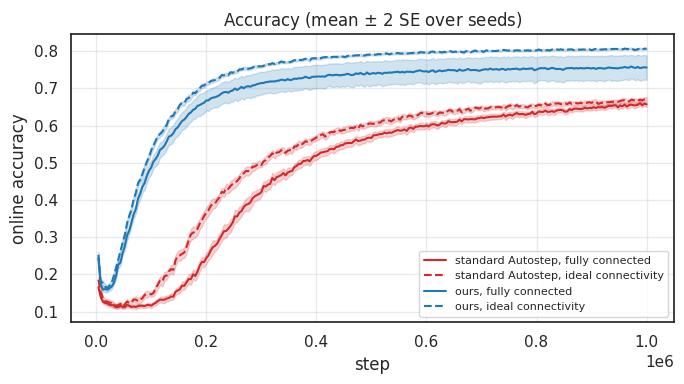

standard Autostep, fully connected     online accuracy 65.34%
standard Autostep, ideal connectivity  online accuracy 66.56%
ours, fully connected                  online accuracy 75.56%
ours, ideal connectivity               online accuracy 80.59%
H1, ours fully connected vs ideal connectivity: -5.0 points (± 3.3): failed
H2, standard Autostep fully connected vs ideal connectivity: -1.2 points (± 0.6): held


In [7]:
runs = {'standard Autostep, fully connected': run('fully connected', ours=False),
        'standard Autostep, ideal connectivity': run('ideal connectivity', ours=False),
        'ours, fully connected': run('fully connected', ours=True),
        'ours, ideal connectivity': run('ideal connectivity', ours=True)}
# Color by learner; dashed for the ideal connectivity.
STYLES = {'standard Autostep, fully connected': ('tab:red', '-'),
          'standard Autostep, ideal connectivity': ('tab:red', '--'),
          'ours, fully connected': ('tab:blue', '-'), 'ours, ideal connectivity': ('tab:blue', '--')}

window_ends = np.arange(1, N_WINDOWS + 1) * (NUM_STEPS // N_WINDOWS)
plt.figure(figsize=(7, 4))
for label, res in runs.items():
    mean = res['accuracy'].mean(0)
    sem = res['accuracy'].std(0) / np.sqrt(N_SEEDS)
    color, linestyle = STYLES[label]
    plt.plot(window_ends, mean, color=color, ls=linestyle, lw=1.5, label=label)
    plt.fill_between(window_ends, mean - 2 * sem, mean + 2 * sem, color=color, alpha=0.2)
plt.xlabel('step')
plt.ylabel('online accuracy')
plt.title('Accuracy (mean $\\pm$ 2 SE over seeds)')
plt.grid(alpha=0.4)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Each seed's online accuracy over the last FINAL_FRACTION of training.
final = slice(-round(N_WINDOWS * FINAL_FRACTION), None)
accuracy = {label: res['accuracy'][:, final].mean(1) for label, res in runs.items()}
for label, a in accuracy.items():
    print(f'{label:<38} online accuracy {a.mean():.2%}')


def gap(learner):
    # The per-seed gap in accuracy of the fully connected run to the ideal connectivity on the same seed: its mean and
    # 2 SE.
    g = accuracy[f'{learner}, fully connected'] - accuracy[f'{learner}, ideal connectivity']
    return g.mean(), 2 * g.std() / np.sqrt(N_SEEDS)


held = lambda ok: 'held' if ok else 'failed'
h1, h1_se = gap('ours')
h2, h2_se = gap('standard Autostep')
print(f'H1, ours fully connected vs ideal connectivity: {100 * h1:+.1f} points (± {100 * h1_se:.1f}): '
      f'{held(h1 >= -ACCURACY_TOLERANCE)}')
print(f'H2, standard Autostep fully connected vs ideal connectivity: {100 * h2:+.1f} points (± {100 * h2_se:.1f}): '
      f'{held(h2 < -ACCURACY_TOLERANCE)}')

### Diagnostics: mixing and unit allocation

Path purity and allocation over training for the fully connected runs (mean $\pm$ 2 SE over seeds).

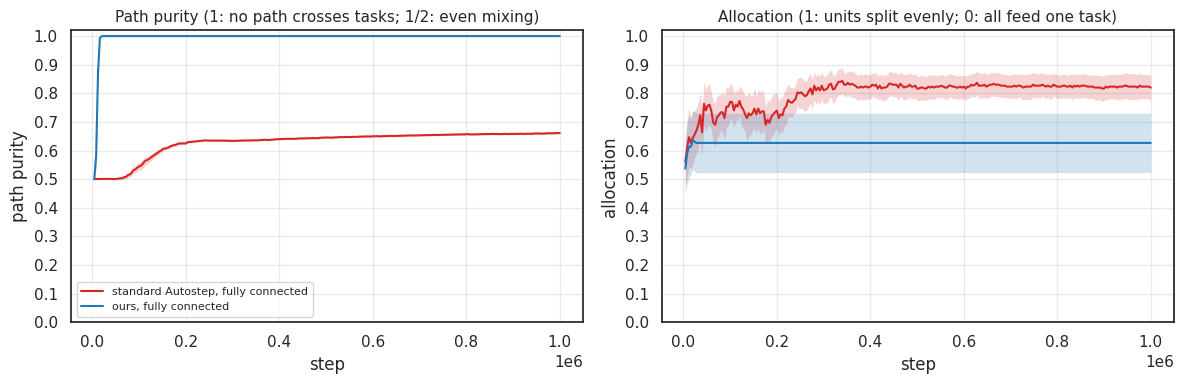

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
panels = [('purity', 'path purity', 'Path purity (1: no path crosses tasks; 1/2: even mixing)'),
          ('allocation', 'allocation', 'Allocation (1: units split evenly; 0: all feed one task)')]
for ax, (key, ylabel, title) in zip(axes, panels):
    for label in ('standard Autostep, fully connected', 'ours, fully connected'):
        v = runs[label][key]                                                 # (seed, window)
        color, _ = STYLES[label]
        mean, sem = v.mean(0), v.std(0) / np.sqrt(N_SEEDS)
        ax.plot(window_ends, mean, color=color, lw=1.5, label=label)
        ax.fill_between(window_ends, mean - 2 * sem, mean + 2 * sem, color=color, alpha=0.2, lw=0)
    ax.set_ylim(0, 1.02)
    ax.yaxis.set_major_locator(plt.MultipleLocator(0.1))
    ax.set_xlabel('step')
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=11)
    ax.grid(alpha=0.4)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

## Results

- **H1 failed.** Fully connected, ours reaches 75.6% online accuracy against 80.6% with ideal connectivity: −5.0
  points (± 3.3, 2 SE over paired seeds).
- **H2 held.** Fully connected, standard Autostep is −1.2 points (± 0.6): 65.3% against 66.6%.
- Ours beats standard Autostep on both networks, by 10.2 points fully connected and by 14.0 with ideal connectivity.
- **Diagnostics.** Ours never mixes the tasks: its path purity reaches 1 within about 20k steps, against about 0.66
  for standard Autostep. But it splits its hidden units unevenly, and early: its allocation settles at about 0.63
  within about 20k steps and never changes, while standard Autostep's reaches about 0.82. So ours' gap to the ideal
  network comes from allocation: in a debugging run with 5 units per task, fixing the split at 5/5 closed the gap.

## Question 2: do shadow weights to a single output solve this?

Fully connected, our method falls short of the ideal connectivity because it splits the hidden units unevenly between
the tasks early on, and never revises the split; its units do not mix the tasks (in a debugging run with 5 units
per task, fixing the split at 5/5 while still allowing mixing matched the ideal network). A first fix: pair each hidden unit with one output (the network has one unit per
output; unit $j$ with output $j$), and give that connection a fixed shadow weight of $+1$ or $-1$, drawn at random at
the start, used only in the backward pass. The forward pass is unchanged and the output weights keep their true
gradients. Two versions:
- *shadow feedback*: unit $j$'s gradient comes only from output $j$, through the shadow weight. Each task then has as
  many units learning its features as it has outputs, so the split is even by construction, without knowing the tasks.
- *shadow feedback + backprop*: unit $j$'s gradient comes from every output through the output weights, as in backprop,
  except that the weight from output $j$ counts as the shadow weight unless the real one is larger in magnitude.

Both use our learner, fully connected, and are compared with the fully connected and ideal runs at the top.

**H3**: fully connected with shadow feedback is at most 1 point below ideal connectivity.

**H4**: fully connected with shadow feedback + backprop is at most 1 point below ideal connectivity.

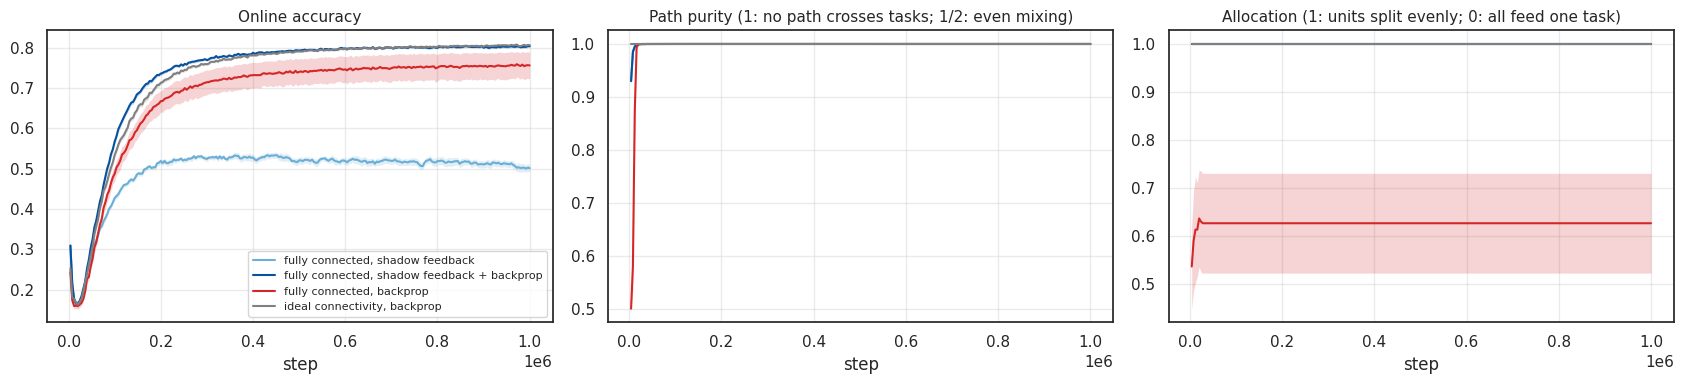

fully connected, shadow feedback              online accuracy 50.91%
fully connected, shadow feedback + backprop   online accuracy 80.24%
fully connected, backprop                     online accuracy 75.56%
ideal connectivity, backprop                  online accuracy 80.59%
H3, fully connected, shadow feedback vs ideal connectivity, backprop: -29.7 points (± 0.7): failed
H4, fully connected, shadow feedback + backprop vs ideal connectivity, backprop: -0.4 points (± 0.2): held


In [9]:
def plot_runs(runs, colors):
    # Accuracy, path purity and allocation over training for each run in `runs` (mean +- 2 SE over seeds).
    fig, axes = plt.subplots(1, 3, figsize=(17, 4))
    for ax, (key, title) in zip(axes, [('accuracy', 'Online accuracy'),
                                       ('purity', 'Path purity (1: no path crosses tasks; 1/2: even mixing)'),
                                       ('allocation', 'Allocation (1: units split evenly; 0: all feed one task)')]):
        for label, res in runs.items():
            mean, sem = res[key].mean(0), res[key].std(0) / np.sqrt(N_SEEDS)
            ax.plot(window_ends, mean, color=colors[label], lw=1.5, label=label)
            ax.fill_between(window_ends, mean - 2 * sem, mean + 2 * sem, color=colors[label], alpha=0.2, lw=0)
        ax.yaxis.set_major_locator(plt.MultipleLocator(0.1))
        ax.set_xlabel('step')
        ax.set_title(title, fontsize=11)
        ax.grid(alpha=0.4)
    axes[0].legend(fontsize=8)
    fig.tight_layout()
    plt.show()


def final_accuracy(res):
    return res['accuracy'][:, final].mean(1)                 # each seed's accuracy over the last FINAL_FRACTION


def report(runs, tests):
    # Prints every run's accuracy, then for each test (name, label, reference) whether `label` is at most
    # ACCURACY_TOLERANCE below `reference` on paired seeds.
    for label, res in runs.items():
        print(f'{label:<45} online accuracy {final_accuracy(res).mean():.2%}')
    for name, label, reference in tests:
        g = final_accuracy(runs[label]) - final_accuracy(runs[reference])
        print(f'{name}, {label} vs {reference}: {100 * g.mean():+.1f} points '
              f'(± {100 * 2 * g.std() / np.sqrt(N_SEEDS):.1f}): {held(g.mean() >= -ACCURACY_TOLERANCE)}')


shadow_runs = {'fully connected, shadow feedback': run('fully connected', True, backward='shadow'),
               'fully connected, shadow feedback + backprop':
                   run('fully connected', True, backward='shadow + backprop'),
               'fully connected, backprop': runs['ours, fully connected'],
               'ideal connectivity, backprop': runs['ours, ideal connectivity']}
plot_runs(shadow_runs, {'fully connected, shadow feedback': '#6baed6', 'fully connected, shadow feedback + backprop':
                        '#08519c', 'fully connected, backprop': 'tab:red', 'ideal connectivity, backprop': 'gray'})
report(shadow_runs, [('H3', 'fully connected, shadow feedback', 'ideal connectivity, backprop'),
                     ('H4', 'fully connected, shadow feedback + backprop', 'ideal connectivity, backprop')])

**Result.** Shadow feedback alone does not solve it (H3 failed): 50.9% online accuracy, −29.7 points (± 0.7) below
ideal connectivity, even though its allocation and path purity are both exactly 1. Each unit is tied to one output,
that is, to one label slot, so it likely has to relearn its feature every time its task's labels are permuted (not yet
tested).

**Shadow feedback + backprop does solve it (H4 held):** 80.2%, −0.4 points (± 0.2) from ideal connectivity, and 4.7
points above backprop in the same network. Its allocation and path purity are exactly 1 in every seed (both lines are
hidden under the ideal network's), and early on it learns faster than the ideal network. The shadow weight guarantees
each unit a gradient from its own output, which keeps the split even; the other outputs' gradients likely let the units
learn features that serve their whole task, and so survive the label permutations.

## Question 3: does generate and test solve this?

Instead of fixing the split by construction, let the network revise it. Every 5000 steps, the hidden unit with the
smallest mean $|$output weight$|$ starts over as a new unit: output weights 0, input weights $U(-\alpha_0, \alpha_0)$,
step-sizes $\alpha_0$, zero Autostep traces, and its running means at their initial values. Our learner, fully
connected, with 20 hidden units, against the same network without it and with the ideal connectivity (the runs at the
top).

**H5**: fully connected with generate and test is at most 1 point below ideal connectivity.

**Diagnostic**, fixed in advance: the share of resets that hit the same unit as the reset before. A new unit starts with
output weights near 0, so it is chosen again unless it has grown them by the next reset.

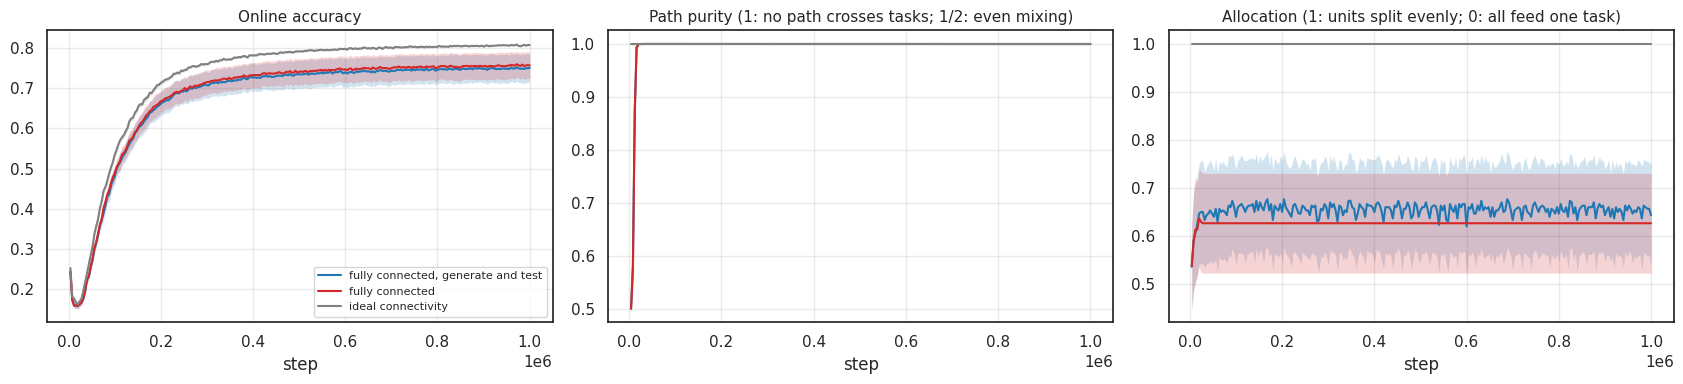

fully connected, generate and test            online accuracy 74.85%
fully connected                               online accuracy 75.56%
ideal connectivity                            online accuracy 80.59%
H5, fully connected, generate and test vs ideal connectivity: -5.7 points (± 3.5): failed
resets per seed 200; share that hit the same unit as the reset before 99%


In [10]:
gnt_runs = {'fully connected, generate and test': run('fully connected', True, reinit_period=REINIT_PERIOD),
            'fully connected': runs['ours, fully connected'],
            'ideal connectivity': runs['ours, ideal connectivity']}
plot_runs(gnt_runs, {'fully connected, generate and test': 'tab:blue', 'fully connected': 'tab:red',
                     'ideal connectivity': 'gray'})
report(gnt_runs, [('H5', 'fully connected, generate and test', 'ideal connectivity')])
res = gnt_runs['fully connected, generate and test']
print(f'resets per seed {res["resets"].mean():.0f}; share that hit the same unit as the reset before '
      f'{res["repeats"].sum() / res["resets"].sum():.0%}')

**Result: no, at a 5k period.** H5 failed: 74.9% online accuracy, −5.7 points (± 3.5) below ideal connectivity, and
0.7 below the same network without generate and test. 99% of the resets hit the unit that was reset just before: a new
unit has not grown its output weights by the next reset, so it is chosen again. Generate and test then keeps one unit
permanently new, and never touches the units that settled the uneven split.

### 3b. The reset period

Every period from 1k to 100k steps: accuracy and allocation over the last 10% of training (mean $\pm$ 2 SE over seeds),
with the fully connected network without generate and test and the ideal connectivity as references.

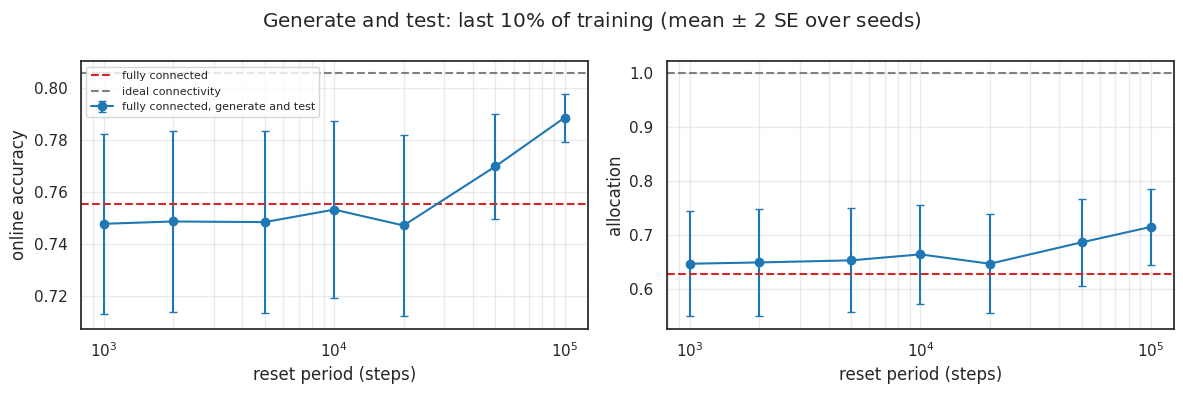

period   1,000: accuracy 74.78%, share of resets that repeat the unit before 100%
period   2,000: accuracy 74.87%, share of resets that repeat the unit before 100%
period   5,000: accuracy 74.85%, share of resets that repeat the unit before 99%
period  10,000: accuracy 75.33%, share of resets that repeat the unit before 99%
period  20,000: accuracy 74.72%, share of resets that repeat the unit before 98%
period  50,000: accuracy 77.00%, share of resets that repeat the unit before 94%
period 100,000: accuracy 78.88%, share of resets that repeat the unit before 86%


In [11]:
sweep = {p: run('fully connected', True, reinit_period=p) for p in REINIT_PERIODS}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (key, ylabel) in zip(axes, [('accuracy', 'online accuracy'), ('allocation', 'allocation')]):
    values = np.stack([sweep[p][key][:, final].mean(1) for p in REINIT_PERIODS])         # (period, seed)
    ax.errorbar(REINIT_PERIODS, values.mean(1), yerr=2 * values.std(1) / np.sqrt(N_SEEDS), color='tab:blue',
                marker='o', lw=1.5, capsize=3, label='fully connected, generate and test')
    for label, color in [('ours, fully connected', 'tab:red'), ('ours, ideal connectivity', 'gray')]:
        ax.axhline(runs[label][key][:, final].mean(), color=color, lw=1.5, ls='--', label=label.replace('ours, ', ''))
    ax.set_xscale('log')
    ax.set_xlabel('reset period (steps)')
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.4, which='both')
axes[0].legend(fontsize=8)
fig.suptitle('Generate and test: last 10% of training (mean $\\pm$ 2 SE over seeds)')
fig.tight_layout()
plt.show()
for p in REINIT_PERIODS:
    print(f'period {p:>7,}: accuracy {final_accuracy(sweep[p]).mean():.2%}, '
          f'share of resets that repeat the unit before {sweep[p]["repeats"].sum() / sweep[p]["resets"].sum():.0%}')

**Result.** From 1k to 20k steps, accuracy stays at 74.7–75.3%, around the network without generate and test (75.6%),
and 98–100% of the resets repeat the unit before. Only long periods help: 77.0% at 50k steps (94% repeats) and 78.9% at
100k (86% repeats), 3.3 points above the network without generate and test but still 1.7 below ideal connectivity. The
best period is the largest one tried.